 The Oh model was fitted to measured bare-soil data and does not explicitly use soil texture as an input. Texture-specific curves below are therefore *scenario simulations*, implemented by assigning illustrative moisture/roughness settings to clay, loam, and sand—not calibrated predictions for those textures. For research-grade results, replace these settings with measured dielectric/moisture and roughness data, and validate against observations.

## Model equations used

Let \(m_v\) be volumetric soil moisture (m³/m³), \(\theta\) incidence angle in degrees, \(s\) RMS height (m), \(l\) correlation length (m), \(k=2\pi/\lambda=2\pi f/c_0\), \(ks\) the dimensionless roughness, and \(kl\) the dimensionless correlation length.

The 2002 Oh semi-empirical model gives:

\[
\sigma^0_{hv}=0.11\,m_v^{0.7}\,(\cos\theta)^{2.2}\,[1-\exp(-0.32(ks)^{1.8})]
\]

\[
q=\frac{\sigma^0_{hv}}{\sigma^0_{vv}}
=0.10\left(\frac{s}{l}+\sin(1.3\theta)\right)^{1.2}
[1-\exp(-0.9(ks)^{0.8})]
\]

\[
\sigma^0_{vv}=\frac{\sigma^0_{hv}}{q}
\]

\[
p=\frac{\sigma^0_{hh}}{\sigma^0_{vv}}
=1-\left(\frac{\theta}{90^\circ}\right)^{0.35m_v^{-0.65}}
\exp[-(ks)^{0.4}]
\]

\[
\sigma^0_{hh}=p\,\sigma^0_{vv}
\]

The equations are implemented with angles converted to radians where required by NumPy trigonometric functions. Outputs are converted to dB using \(10\log_{10}(\sigma^0)\). The original model is an empirical parameterization; its use outside its reported calibration domain should be treated cautiously.


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

C0 = 299_792_458.0  # speed of light (m/s)
BANDS_GHZ = {"S": 3.0, "C": 5.3, "X": 9.6}

def oh_backscatter(mv, theta_deg, rms_height_m, corr_length_m, frequency_ghz):
    """Oh et al. (2002) bare-soil backscatter model. Returns linear sigma0 for HH, VV, HV."""
    mv, theta_deg, rms_height_m, corr_length_m = np.broadcast_arrays(
        np.asarray(mv, dtype=float), np.asarray(theta_deg, dtype=float),
        np.asarray(rms_height_m, dtype=float), np.asarray(corr_length_m, dtype=float)
    )
    if np.any((mv <= 0) | (mv >= 0.35)):
        raise ValueError("mv must be in (0, 0.35), consistent with the model's stated moisture range.")
    if np.any((theta_deg <= 0) | (theta_deg >= 90)):
        raise ValueError("Incidence angle must be between 0 and 90 degrees.")
    if np.any(rms_height_m <= 0) or np.any(corr_length_m <= 0):
        raise ValueError("RMS height and correlation length must be positive.")
    f_hz = frequency_ghz * 1e9
    wavelength = C0 / f_hz
    k = 2 * np.pi / wavelength
    ks = k * rms_height_m
    ratio_sl = rms_height_m / corr_length_m
    theta_rad = np.deg2rad(theta_deg)

    sigma_hv = 0.11 * mv**0.7 * np.cos(theta_rad)**2.2 * (1 - np.exp(-0.32 * ks**1.8))
    q = 0.10 * (ratio_sl + np.sin(1.3 * theta_rad))**1.2 * (1 - np.exp(-0.9 * ks**0.8))
    sigma_vv = sigma_hv / np.maximum(q, 1e-12)
    p = 1 - (theta_deg / 90.0)**(0.35 * mv**(-0.65)) * np.exp(-(ks**0.4))
    sigma_hh = p * sigma_vv
    return {"HH": np.maximum(sigma_hh, 1e-12), "VV": np.maximum(sigma_vv, 1e-12),
            "HV": np.maximum(sigma_hv, 1e-12)}

def to_db(x):
    return 10 * np.log10(np.maximum(x, 1e-12))

# Illustrative scenario values; change to measured values for your site.
# Values are not universal texture constants.
SOILS = {
    "Clay":  {"mv": 0.25, "s_cm": 1.0, "l_cm": 8.0},
    "Loamy": {"mv": 0.18, "s_cm": 1.5, "l_cm": 7.0},
    "Sandy": {"mv": 0.08, "s_cm": 0.7, "l_cm": 5.0},
}
POLARIZATIONS = ["HH", "VV"]


## 1. Soil moisture vs. backscatter
Hold incidence angle and roughness fixed for each illustrative soil scenario. Compare all three polarizations and all three bands.

In [25]:
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
    "figure.titlesize": 18,
})

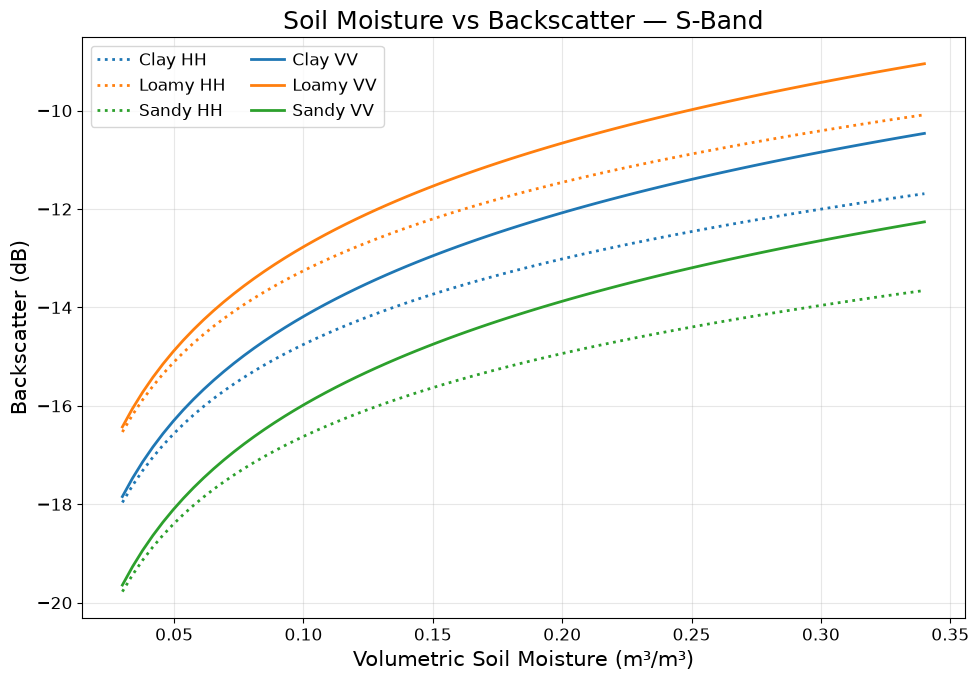

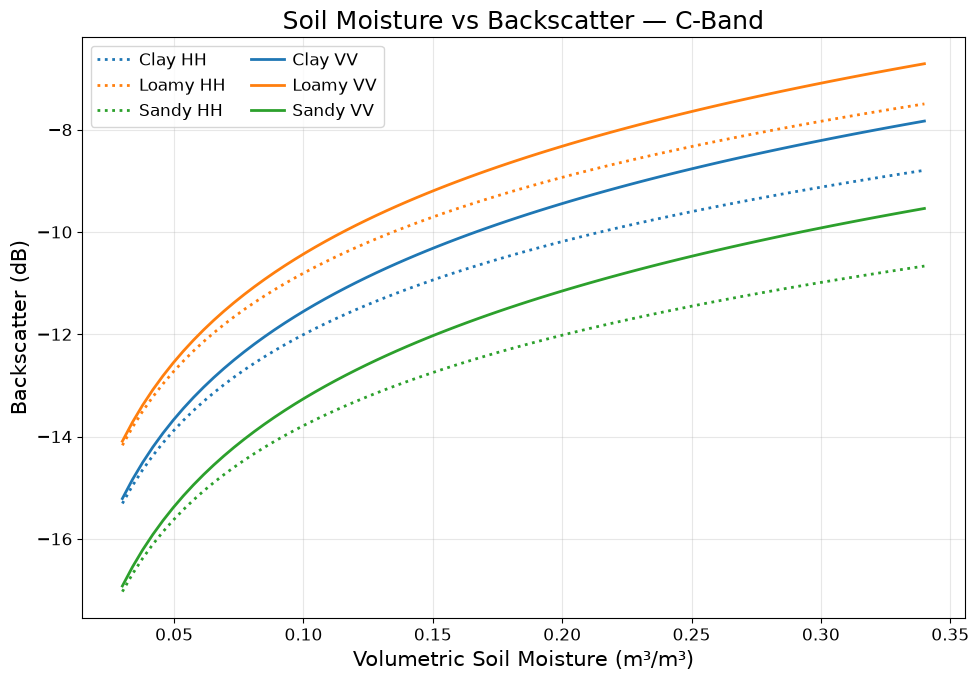

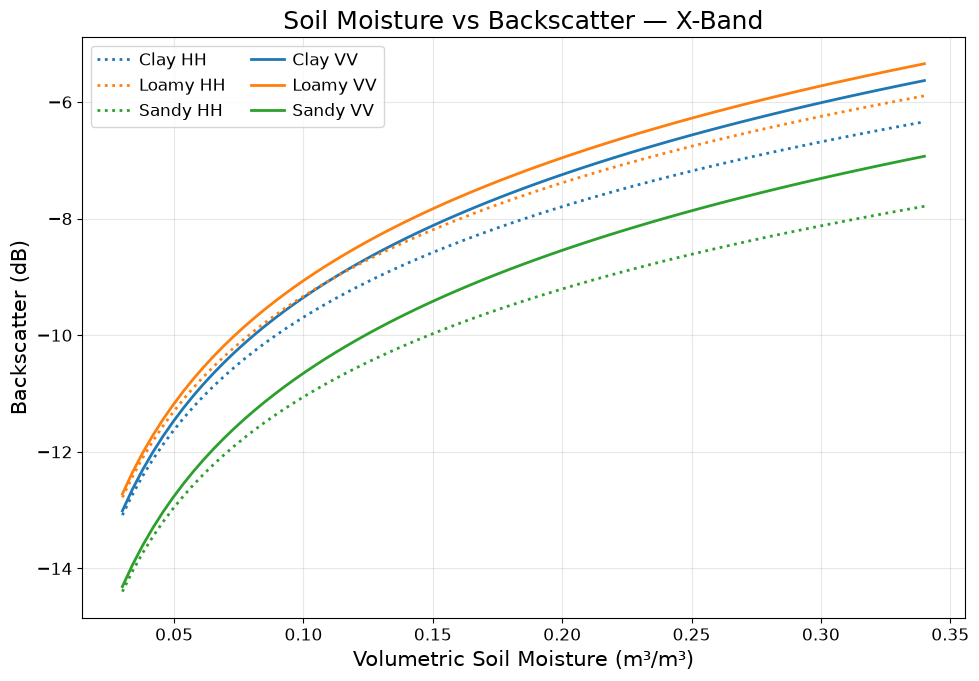

In [32]:

moisture = np.linspace(0.03, 0.34, 80)
theta_fixed = 40.0

soil_colors = {
    "Clay": "tab:blue",
    "Loamy": "tab:orange",
    "Sandy": "tab:green"
}

for band in ["S", "C", "X"]:
    # Assign the figure and axes explicitly
    fig, ax = plt.subplots(figsize=(10, 7))


    for soil, pars in SOILS.items():
        out = oh_backscatter(
            moisture,
            theta_fixed,
            pars["s_cm"] / 100,
            pars["l_cm"] / 100,
            BANDS_GHZ[band]
        )

        # HH polarization: dotted line
        plt.plot(
            moisture, to_db(out["HH"]),
            linestyle=":",
            color=soil_colors[soil],
            linewidth=2,
            label=f"{soil} HH"
        )

        # VV polarization: solid line
        plt.plot(
            moisture, to_db(out["VV"]),
            linestyle="-",
            color=soil_colors[soil],
            linewidth=2,
            label=f"{soil} VV"
        )

    plt.title(f"Soil Moisture vs Backscatter — {band}-Band")
    plt.xlabel("Volumetric Soil Moisture (m³/m³)")
    plt.ylabel("Backscatter (dB)")
    plt.grid(True, alpha=0.3)
    handles, labels = plt.gca().get_legend_handles_labels()

    order = [
        "Clay HH", 
        "Loamy HH",
        "Sandy HH",
        "Clay VV",
        "Loamy VV",
        "Sandy VV"
    ]

    label_to_handle = dict(zip(labels, handles))

    plt.legend(
        [label_to_handle[label] for label in order],
        order,
        ncol=2,
        columnspacing=1.5,
        handletextpad=0.5
    )
    
    filename = f"SMvsBS_{band}.png"

    fig.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.tight_layout()
    plt.show()


## 2. Incidence angle vs. backscatter
Hold moisture and roughness fixed. The angle sweep is 20°–50°, within the broad range used in the Oh-model source database.

Saved: IAvsBS_S.png


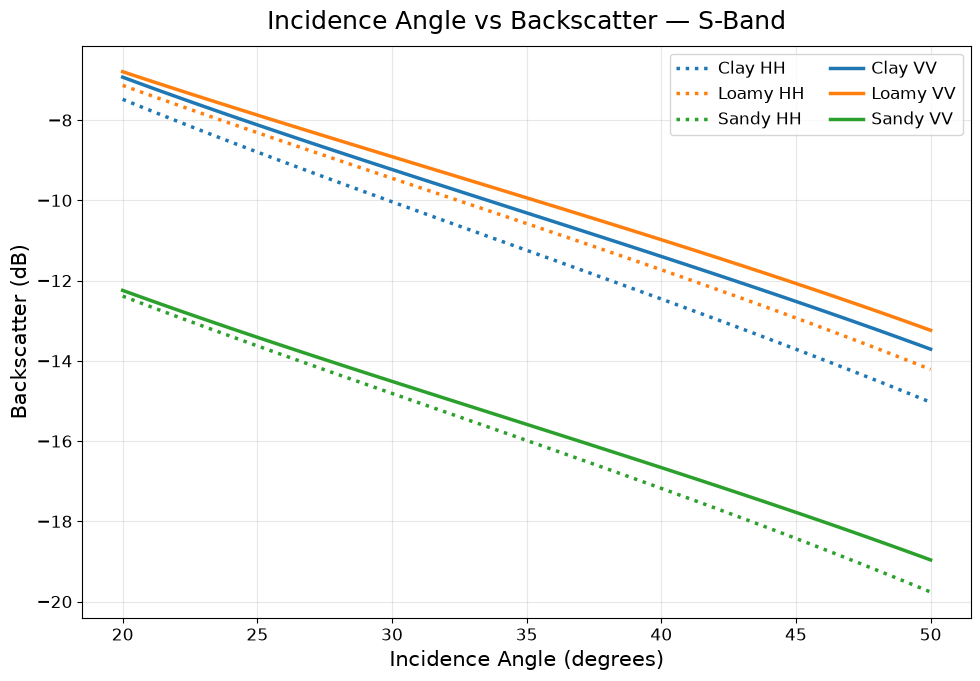

Saved: IAvsBS_C.png


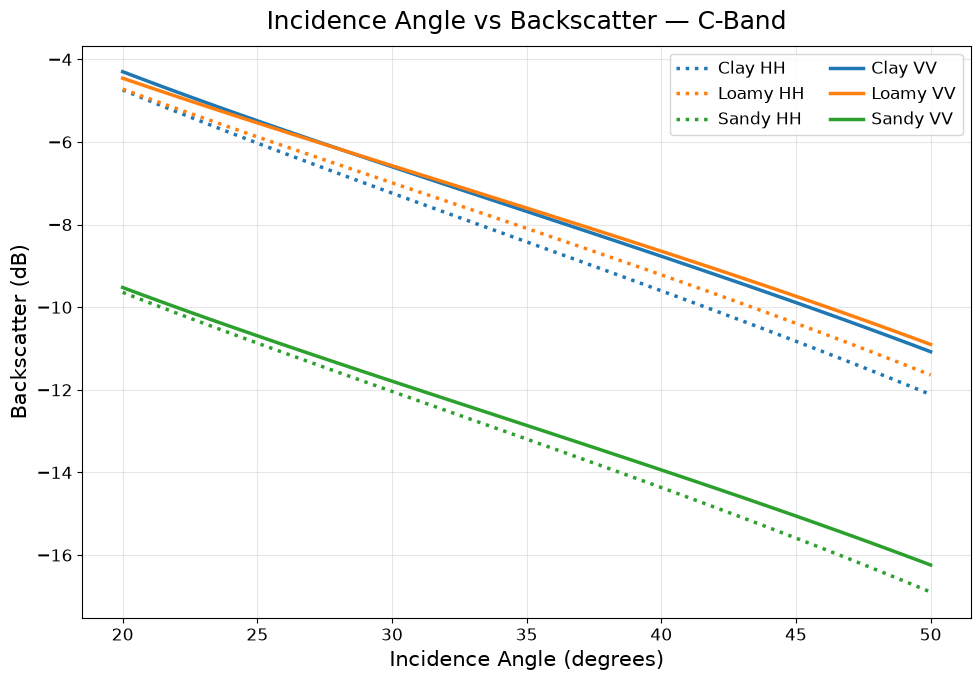

Saved: IAvsBS_X.png


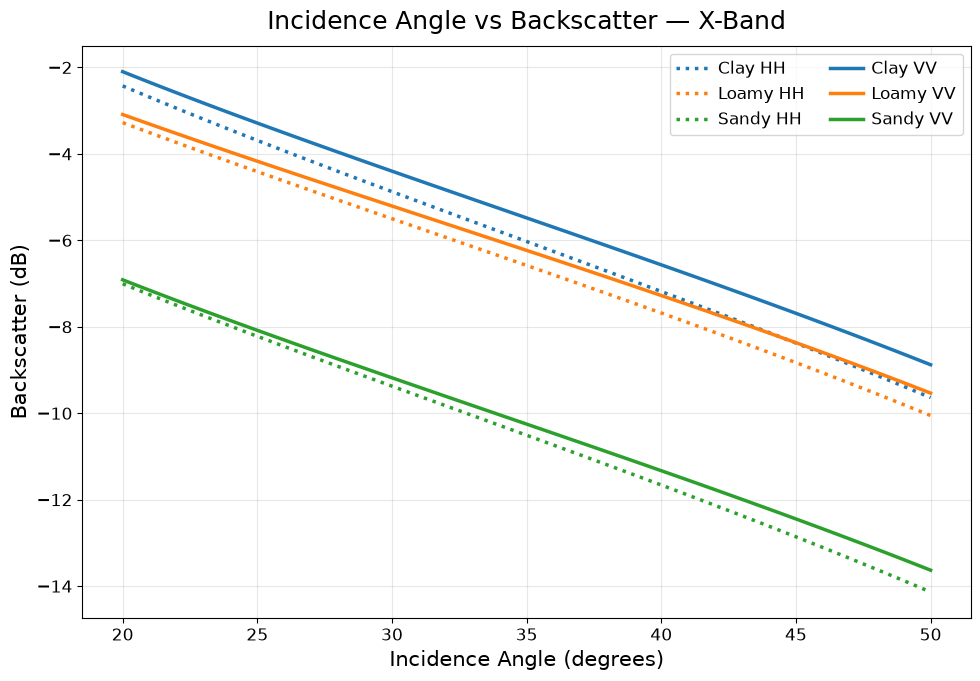

In [31]:
angles = np.linspace(20, 50, 80)

soil_colors = {
    "Clay": "tab:blue",
    "Loamy": "tab:orange",
    "Sandy": "tab:green",
}

for band in ["S", "C", "X"]:

    # Assign the figure and axes explicitly
    fig, ax = plt.subplots(figsize=(10, 7))

    for soil, pars in SOILS.items():
        out = oh_backscatter(
            pars["mv"],
            angles,
            pars["s_cm"] / 100,
            pars["l_cm"] / 100,
            BANDS_GHZ[band]
        )

        # HH polarization: dotted line
        ax.plot(
            angles,
            to_db(out["HH"]),
            linestyle=":",
            color=soil_colors[soil],
            linewidth=2.5,
            label=f"{soil} HH"
        )

        # VV polarization: solid line
        ax.plot(
            angles,
            to_db(out["VV"]),
            linestyle="-",
            color=soil_colors[soil],
            linewidth=2.5,
            label=f"{soil} VV"
        )

    ax.set_title(
        f"Incidence Angle vs Backscatter — {band}-Band",
        pad=12
    )
    ax.set_xlabel("Incidence Angle (degrees)")
    ax.set_ylabel("Backscatter (dB)")
    ax.grid(True, alpha=0.3)

    handles, labels = ax.get_legend_handles_labels()

    order = [
        "Clay HH",
        "Loamy HH",
        "Sandy HH",
        "Clay VV",
        "Loamy VV",
        "Sandy VV"
    ]

    label_to_handle = dict(zip(labels, handles))

    ax.legend(
        [label_to_handle[label] for label in order],
        order,
        ncol=2,
        columnspacing=1.5,
        handletextpad=0.5,
        frameon=True
    )

    # Adjust layout before saving
    fig.tight_layout()

    # Save the figure
    filename = f"IAvsBS_{band}.png"
    fig.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    print(f"Saved: {filename}")

    plt.show()
    plt.close(fig)

## 3. RMS roughness vs. backscatter
Vary RMS height \(s\), keeping correlation length, moisture, and incidence angle fixed for each soil scenario. Because the frequency enters through \(ks\), band sensitivity changes with wavelength.

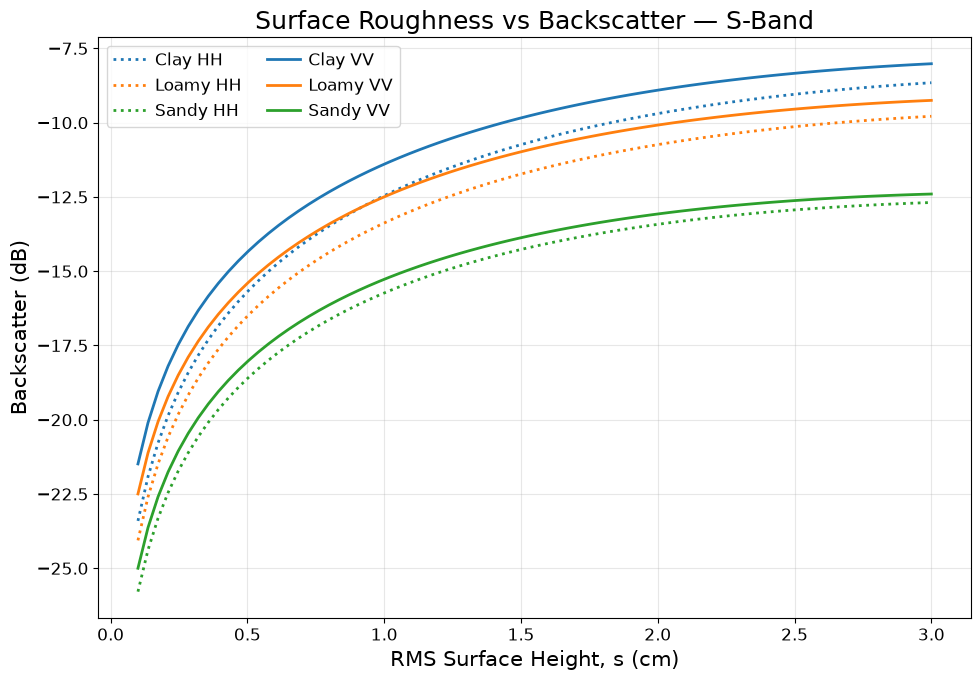

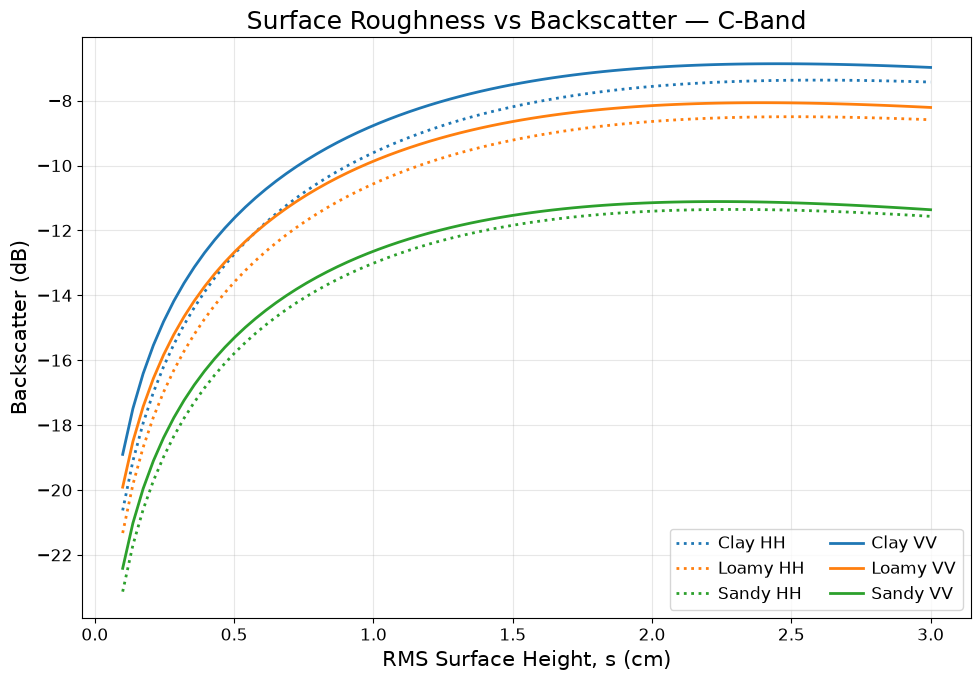

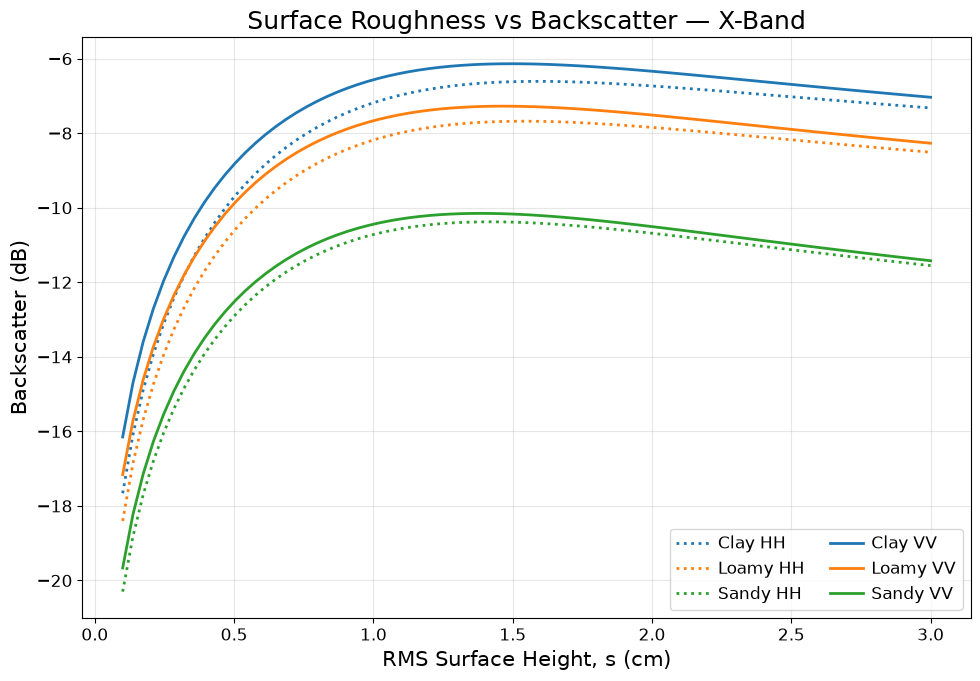

In [33]:

roughness_cm = np.linspace(0.1, 3.0, 80)
theta_fixed = 40.0

soil_colors = {
    "Clay": "tab:blue",
    "Loamy": "tab:orange",
    "Sandy": "tab:green"
}

for band in ["S", "C", "X"]:
    # Assign the figure and axes explicitly
    fig, ax = plt.subplots(figsize=(10, 7))


    for soil, pars in SOILS.items():
        out = oh_backscatter(
            pars["mv"],
            theta_fixed,
            roughness_cm / 100,
            pars["l_cm"] / 100,
            BANDS_GHZ[band]
        )

        # HH polarization: dotted line
        plt.plot(
            roughness_cm,
            to_db(out["HH"]),
            linestyle=":",
            color=soil_colors[soil],
            linewidth=2,
            label=f"{soil} HH"
        )

        # VV polarization: solid line
        plt.plot(
            roughness_cm,
            to_db(out["VV"]),
            linestyle="-",
            color=soil_colors[soil],
            linewidth=2,
            label=f"{soil} VV"
        )

    plt.title(f"Surface Roughness vs Backscatter — {band}-Band")
    plt.xlabel("RMS Surface Height, s (cm)")
    plt.ylabel("Backscatter (dB)")
    plt.grid(True, alpha=0.3)
    
    handles, labels = plt.gca().get_legend_handles_labels()

    order = [
        "Clay HH", 
        "Loamy HH",
        "Sandy HH",
        "Clay VV",
        "Loamy VV",
        "Sandy VV"
    ]

    label_to_handle = dict(zip(labels, handles))

    plt.legend(
        [label_to_handle[label] for label in order],
        order,
        ncol=2,
        columnspacing=1.5,
        handletextpad=0.5
    )
    filename = f"RMSvsBS_{band}.png"

    fig.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.tight_layout()
    plt.show()


## Export simulation tables

This cell exports long-format CSV files for all three sweeps. These are model-generated scenario outputs, not measured observations.

In [29]:
rows = []
for soil, pars in SOILS.items():
    for band, freq in BANDS_GHZ.items():
        # Moisture sweep
        res = oh_backscatter(moisture, 40.0, pars["s_cm"]/100, pars["l_cm"]/100, freq)
        for i, mv in enumerate(moisture):
            for pol in POLARIZATIONS:
                rows.append({"experiment":"moisture", "soil":soil, "band":band, "frequency_GHz":freq,
                             "polarization":pol, "moisture_m3_m3":mv, "incidence_deg":40.0,
                             "rms_height_cm":pars["s_cm"], "correlation_length_cm":pars["l_cm"],
                             "backscatter_dB":float(to_db(res[pol][i]))})
        # Angle sweep
        res = oh_backscatter(pars["mv"], angles, pars["s_cm"]/100, pars["l_cm"]/100, freq)
        for i, ang in enumerate(angles):
            for pol in POLARIZATIONS:
                rows.append({"experiment":"incidence_angle", "soil":soil, "band":band, "frequency_GHz":freq,
                             "polarization":pol, "moisture_m3_m3":pars["mv"], "incidence_deg":ang,
                             "rms_height_cm":pars["s_cm"], "correlation_length_cm":pars["l_cm"],
                             "backscatter_dB":float(to_db(res[pol][i]))})
        # Roughness sweep
        res = oh_backscatter(pars["mv"], 40.0, roughness_cm/100, pars["l_cm"]/100, freq)
        for i, rough in enumerate(roughness_cm):
            for pol in POLARIZATIONS:
                rows.append({"experiment":"roughness", "soil":soil, "band":band, "frequency_GHz":freq,
                             "polarization":pol, "moisture_m3_m3":pars["mv"], "incidence_deg":40.0,
                             "rms_height_cm":rough, "correlation_length_cm":pars["l_cm"],
                             "backscatter_dB":float(to_db(res[pol][i]))})

results = pd.DataFrame(rows)
results.to_csv("oh_model_simulation_outputs.csv", index=False)
results.head(), results.shape


(  experiment  soil band  frequency_GHz polarization  moisture_m3_m3  \
 0   moisture  Clay    S            3.0           HH        0.030000   
 1   moisture  Clay    S            3.0           VV        0.030000   
 2   moisture  Clay    S            3.0           HH        0.033924   
 3   moisture  Clay    S            3.0           VV        0.033924   
 4   moisture  Clay    S            3.0           HH        0.037848   
 
    incidence_deg  rms_height_cm  correlation_length_cm  backscatter_dB  
 0           40.0            1.0                    8.0      -17.963557  
 1           40.0            1.0                    8.0      -17.843658  
 2           40.0            1.0                    8.0      -17.618798  
 3           40.0            1.0                    8.0      -17.469953  
 4           40.0            1.0                    8.0      -17.315245  ,
 (4320, 10))

**Reference:** Y. Oh, K. Sarabandi, and F. T. Ulaby, “Semi-Empirical Model of the Ensemble-Averaged Differential Mueller Matrix for Microwave Backscattering From Bare Soil Surfaces,” *IEEE Transactions on Geoscience and Remote Sensing*, 40(6), 1348–1355, 2002.


In [30]:
scenario_df.to_csv("oh2002_scenario_results.csv", index=False)
moisture_df.to_csv("oh2002_moisture_sweep.csv", index=False)
roughness_df.to_csv("oh2002_roughness_sweep.csv", index=False)
angle_df.to_csv("oh2002_angle_sweep.csv", index=False)
frequency_df.to_csv("oh2002_frequency_sweep.csv", index=False)
print("Exported scenario and sweep CSV files to the current working directory.")


Exported scenario and sweep CSV files to the current working directory.


## 6. Interpretation, assumptions, and reference

- This implementation uses the **Oh 2002** form with moisture-based \(p\), correlation-length-dependent \(q\), and the empirical \(\sigma^0_{VH}\) expression. Do not mix these terms with the Oh 1992 or Oh 2004 equations.
- The equations represent normalized backscatter coefficients in linear power. Conversion to dB is \(10\log_{10}(\sigma^0)\).
- This is a **bare-soil** model. It does not model vegetation attenuation, subsurface target returns, vertical moisture profiles, interferometric phase/coherence, or soil dielectric dispersion explicitly.
- Parameter validity is empirical. Review the model's stated domain in the original source before interpreting extreme moisture, roughness, angles, or frequencies. This notebook checks basic physical inputs but does not certify every combination as inside the published calibration domain.
- The inversion example assumes known surface roughness and correlation length. Soil moisture and roughness can be confounded in real retrievals; use independent roughness information or multi-angle/polarimetric observations where possible.

Reference for the Oh 2002 equations: Y. Oh et al., “A novel model for the backscattering coefficient of soil surfaces,” commonly cited in later evaluations of the Oh family of semi-empirical models. A useful equation summary and model-version comparison is available in [Evaluation of the Oh, Dubois and IEM Backscatter Models Using a Large Dataset of SAR Data and Experimental Soil Measurements](https://www.mdpi.com/2073-4441/9/1/38). The project report *Electromagnetic Wave Interaction with Soil and Soil Moisture* also distinguishes the 1992 parameterization from later Oh formulations.
